# Who Said "Stop"? — Phase-only GMM-UBM speaker verification (final submission)

**Kaggle:** `akspai418` · **Roll no.:** `BT24056`

This notebook is the complete, self-contained implementation that produces the final
Kaggle submission.  Running it top to bottom:

1. extracts **phase-derived features** (no magnitude features) for every recording,
2. trains a **128-component diagonal GMM-UBM with EM** on background speakers,
3. builds speaker models by **mean-only MAP adaptation** (relevance factor `r = 16`),
4. scores every trial with the **average per-frame log-likelihood ratio**,
5. normalises scores with **adaptive S-norm** (background cohort) and fuses
   complementary phase representations,
6. reports development-set EER / DET, and writes the submission CSV.

**Implementation constraint.** All numerical work — STFT, phase processing, VAD, k-means,
EM, MAP, LLR scoring, normalisation and metrics — uses **`torch` / `torchaudio` only**.
No NumPy, SciPy, scikit-learn or librosa.  Python's standard library is used for file
handling (`csv`, `os`), and `matplotlib` only to draw a figure from values that torch
computed.

The design choices below were selected on an *eval-mirroring bench* (10 dev enrolment
rotations + 4-fold speaker-disjoint background cross-validation, ~2,300 genuine trials),
not on the 196 genuine official dev trials alone — see the last section and
`scripts/08`–`12` in the repository.

In [1]:
import csv, glob, math, os, time
from dataclasses import dataclass, replace
from typing import Dict, List, Sequence, Tuple

import torch
import torchaudio

torch.set_num_threads(max(1, min(8, os.cpu_count() or 1)))
SEED = 2026          # same seed the organisers used for their speaker split
SR = 16000
print("torch", torch.__version__, "| torchaudio", torchaudio.__version__,
      "| threads", torch.get_num_threads())


def find_data_dir() -> str:
    """Local layout (data/) or the Kaggle competition input directory."""
    cands = [os.environ.get("SV_DATA_DIR", ""), "data", "../data",
             "/kaggle/input/who-said-stop-a-gmm-ubm-speaker-verification-competition"]
    cands += [os.path.dirname(p) for p in glob.glob("/kaggle/input/**/background.csv",
                                                     recursive=True)]
    for c in cands:
        if c and os.path.exists(os.path.join(c, "background.csv")):
            return os.path.abspath(c)
    raise FileNotFoundError("cannot find background.csv; set SV_DATA_DIR")


DATA_DIR = find_data_dir()
AUDIO_DIR = next(d for d in (os.path.join(DATA_DIR, "audio", "audio"),
                             os.path.join(DATA_DIR, "audio"), DATA_DIR)
                 if glob.glob(os.path.join(d, "*.wav")))
ON_KAGGLE = os.path.isdir("/kaggle/working")
SUB_PATH = "/kaggle/working/submission.csv" if ON_KAGGLE else "submissions/final_submission.csv"
DEV_PATH = "/kaggle/working/dev_results.csv" if ON_KAGGLE else "results/dev_results_final.csv"
CACHE_DIR = "/kaggle/working/nb_cache" if ON_KAGGLE else "nb_cache"
for d in (CACHE_DIR, os.path.dirname(SUB_PATH), os.path.dirname(DEV_PATH)):
    os.makedirs(d, exist_ok=True)
print("data :", DATA_DIR, "\naudio:", AUDIO_DIR, "\nsubmission ->", SUB_PATH)

torch 2.15.0 | torchaudio 2.11.1 | threads 8
data : /Users/akspai/mla4/data 
audio: /Users/akspai/mla4/data/audio/audio 
submission -> submissions/final_submission.csv


## 1. Data and speaker-disjoint background splits

* `background.csv` — 786 background speakers: the **only** data used to train the UBM, fit
  feature normalisation and build score-normalisation cohorts.
* Background speakers are split **by speaker** with seed 2026: 90 % train the UBM, 10 % are
  held out.  The score-normalisation cohort is 150 UBM-split speakers with ≥ 3 recordings
  (3 recordings each).
* Evaluation recordings are used only as the designated enrolment utterances and as trial
  test recordings; nothing is fitted on them.

In [2]:
def read_csv(name: str) -> List[Dict[str, str]]:
    with open(os.path.join(DATA_DIR, name), newline="") as fh:
        return list(csv.DictReader(fh))


BACKGROUND = read_csv("background.csv")
ENROL = {s: read_csv(f"{s}_enrol.csv") for s in ("dev", "eval")}
TRIALS = {s: read_csv(f"{s}_trials.csv") for s in ("dev", "eval")}


def speaker_files(rows) -> Dict[str, List[str]]:
    out: Dict[str, List[str]] = {}
    for r in rows:
        out.setdefault(r["speaker_id"], []).append(r["file_id"])
    return {k: sorted(v) for k, v in out.items()}


def enrol_map(split: str, n_enrol: int = 3) -> Dict[str, List[str]]:
    """speaker -> its designated enrolment files ordered by enrol_index."""
    out: Dict[str, List[Tuple[int, str]]] = {}
    for r in ENROL[split]:
        if int(r["enrol_index"]) < n_enrol:
            out.setdefault(r["speaker_id"], []).append((int(r["enrol_index"]), r["file_id"]))
    return {s: [f for _, f in sorted(v)] for s, v in out.items()}


def background_splits(heldout_frac=0.10, cohort_size=150, cohort_min=3, seed=SEED):
    spk2files = speaker_files(BACKGROUND)
    spks = sorted(spk2files)
    g = torch.Generator().manual_seed(seed)
    spks = [spks[i] for i in torch.randperm(len(spks), generator=g).tolist()]
    n_held = int(round(heldout_frac * len(spks)))
    held_spk, ubm_spk = spks[:n_held], spks[n_held:]
    ubm_files = [f for s in ubm_spk for f in spk2files[s]]
    held_files = [f for s in held_spk for f in spk2files[s]]
    cohort = {s: spk2files[s][:cohort_min] for s in ubm_spk
              if len(spk2files[s]) >= cohort_min}
    cohort = {s: cohort[s] for s in sorted(cohort)[:cohort_size]}
    return ubm_files, held_files, cohort


UBM_FILES, HELD_FILES, COHORT = background_splits()
COHORT_UTTS = [f for v in COHORT.values() for f in v]
ALL_FILES = sorted({r["file_id"] for r in BACKGROUND}
                   | {r["file_id"] for s in ENROL for r in ENROL[s]}
                   | {r["test_file"] for s in TRIALS for r in TRIALS[s]})
n_gen = sum(int(t["label"]) == 1 for t in TRIALS["dev"])
print(f"background: {len(speaker_files(BACKGROUND))} speakers, {len(BACKGROUND)} files"
      f" -> UBM split {len(UBM_FILES)} files, held-out {len(HELD_FILES)} files,"
      f" cohort {len(COHORT)} speakers")
print(f"dev  : {len(enrol_map('dev'))} targets, {len(TRIALS['dev'])} trials "
      f"({n_gen} genuine, {len(TRIALS['dev']) - n_gen} impostor)")
print(f"eval : {len(enrol_map('eval'))} targets, {len(TRIALS['eval'])} trials")
print(f"recordings referenced: {len(ALL_FILES)}")

background: 786 speakers, 1436 files -> UBM split 1287 files, held-out 149 files, cohort 150 speakers
dev  : 97 targets, 1824 trials (196 genuine, 1628 impostor)
eval : 179 targets, 3524 trials
recordings referenced: 3601


In [3]:
import wave


def load_wav(file_id: str) -> torch.Tensor:
    """Mono float32 waveform.  torchaudio first; stdlib `wave` + torch fallback."""
    path = os.path.join(AUDIO_DIR, f"{file_id}.wav")
    try:
        wav, sr = torchaudio.load(path)
    except Exception:
        with wave.open(path, "rb") as wf:
            n_ch, sr = wf.getnchannels(), wf.getframerate()
            raw = wf.readframes(wf.getnframes())
        pcm = torch.frombuffer(bytearray(raw), dtype=torch.int16)
        wav = pcm.to(torch.float32).div_(32768.0).view(-1, n_ch).t().contiguous()
    assert sr == SR, (file_id, sr)
    wav = wav.mean(0) if wav.shape[0] > 1 else wav[0]
    return wav.to(torch.float32)

## 2. Phase-based features

**Why phase differences.**  The organisers prepended 0–30 ms of random audio to every clip.
A time shift of `d` samples multiplies DFT bin `k` by `exp(-j2πkd/N)`, so the *absolute*
phase spectrum is scrambled per utterance.  Both streams used here are built from phase
*differences* in which that term cancels:

* **IFD — instantaneous-frequency deviation (temporal / baseband phase difference)**
  `Δt(t,k) = princarg(φ(t,k) − φ(t−1,k) − 2πk·hop/N)`.
  The shift term is identical in consecutive frames and cancels **exactly**.  Removing the
  expected advance `2πk·hop/N` (the *baseband* step) leaves how far the local partial
  deviates from the bin centre — fine harmonic / formant placement and glottal-source and
  channel phase characteristics.
* **FDPD — frequency-direction phase difference (finite-difference group delay)**
  `Δf(t,k) = princarg(φ(t,k+1) − φ(t,k))`.  A shift adds the constant `−2πd/N` to every
  bin; it is removed by subtracting the frame's magnitude-weighted circular mean.

**Phase wrapping.**  Every difference is wrapped with `princarg` to `[−π, π)`.  Inside each
of 32 mel bands we then take the **circular mean** of `e^{jΔ}` and keep its real and
imaginary parts `(cos, sin)` — an average of unit vectors, so a value near ±π can never be
averaged into a meaningless 0 the way an arithmetic mean of angles would be.

**Role of magnitude (permitted uses only).**  (1) frame energy for the VAD; (2) `|X|` as a
*reliability weight* inside the band circular mean — phase in a near-empty bin is
numerically meaningless.  A weighted mean of a constant phase returns that phase whatever
the weights, so magnitude cannot become the feature value.  No magnitude spectrum, MFCC or
log-mel value is ever a model input.

**Framing.**  Hann window (16–32 ms depending on the member), **3 ms hop**, zero-padded FFT
(`n_fft` 1024 / 2048).  Zero padding oversamples the spectrum so each mel band averages
more, better-conditioned bins.

**Silence removal.**  Energy VAD: keep frames within 25 dB of the utterance's loudest frame
(at least the 10 loudest frames).  Deltas are computed on contiguous frames *before* VAD so
temporal context is not broken by removed frames.

**Final dimension: 128** = 32 bands × {cos, sin} × {static, Δ}.

In [4]:
@dataclass(frozen=True)
class FeatureConfig:
    stream: str = "ifd"          # "ifd" | "fdpd"
    win_ms: float = 16.0
    hop_ms: float = 3.0
    n_fft: int = 1024
    n_bands: int = 32            # mel bands for the circular band mean
    f_min: float = 60.0
    f_max: float = 7800.0
    vad_rel_db: float = 25.0     # keep frames within X dB of the loudest frame
    vad_min_frames: int = 10
    deltas: int = 1
    delta_width: int = 2

    @property
    def win(self) -> int:
        return int(round(self.win_ms * SR / 1000.0))

    @property
    def hop(self) -> int:
        return int(round(self.hop_ms * SR / 1000.0))

    @property
    def tag(self) -> str:
        return f"{self.stream}_w{self.win}h{self.hop}n{self.n_fft}_mel{self.n_bands}_vad{self.vad_rel_db:g}"


EPS = 1e-10
_FB: Dict[tuple, torch.Tensor] = {}


def mel_band_weights(cfg: FeatureConfig, n_freq: int) -> torch.Tensor:
    """(n_bands, n_freq) triangular mel weights (torchaudio), rows summing to 1."""
    key = (cfg.n_bands, n_freq, cfg.f_min, cfg.f_max)
    if key not in _FB:
        fb = torchaudio.functional.melscale_fbanks(
            n_freqs=n_freq, f_min=cfg.f_min, f_max=cfg.f_max, n_mels=cfg.n_bands,
            sample_rate=SR, norm=None, mel_scale="htk").t()
        _FB[key] = fb / fb.sum(dim=1, keepdim=True).clamp_min(EPS)
    return _FB[key]


def princarg(theta: torch.Tensor) -> torch.Tensor:
    """Wrap to [-pi, pi)."""
    return theta - 2.0 * math.pi * torch.floor(theta / (2.0 * math.pi) + 0.5)


def stft(x: torch.Tensor, cfg: FeatureConfig):
    """Complex STFT (T, n_fft/2+1) and per-frame log energy (dB, VAD only)."""
    win, hop = cfg.win, cfg.hop
    pad = win // 2
    x = torch.nn.functional.pad(x.view(1, 1, -1), (pad, pad), mode="reflect").view(-1)
    if x.numel() < win:
        x = torch.nn.functional.pad(x, (0, win - x.numel()))
    frames = x.unfold(0, win, hop)
    fw = frames * torch.hann_window(win, periodic=False, dtype=frames.dtype)
    logE = torch.log10(fw.pow(2).sum(dim=1) + EPS) * 10.0
    return torch.fft.rfft(fw, n=cfg.n_fft, dim=1), logE


def band_circular_mean(theta: torch.Tensor, weight: torch.Tensor, cfg) -> torch.Tensor:
    """Reliability-weighted circular mean of e^{j theta} per mel band -> [cos | sin]."""
    fb = mel_band_weights(cfg, theta.shape[1])
    den = (weight @ fb.t()).clamp_min(EPS)
    return torch.cat([(torch.cos(theta) * weight) @ fb.t() / den,
                      (torch.sin(theta) * weight) @ fb.t() / den], dim=1)


def stream_ifd(X: torch.Tensor, cfg: FeatureConfig) -> torch.Tensor:
    phi = torch.angle(X)
    k = torch.arange(X.shape[1], dtype=phi.dtype)
    advance = 2.0 * math.pi * k * cfg.hop / cfg.n_fft          # expected phase advance
    d = princarg(phi[1:] - phi[:-1] - advance)
    d = torch.cat([d[:1], d], dim=0)                           # keep T frames
    return band_circular_mean(d, X.abs(), cfg)


def stream_fdpd(X: torch.Tensor, cfg: FeatureConfig) -> torch.Tensor:
    phi = torch.angle(X)
    d = princarg(phi[:, 1:] - phi[:, :-1])
    w = 0.5 * (X.abs()[:, 1:] + X.abs()[:, :-1])
    mc = (torch.cos(d) * w).sum(1, keepdim=True)               # per-frame circular mean
    ms = (torch.sin(d) * w).sum(1, keepdim=True)               # (= the time-origin term)
    d = princarg(d - torch.atan2(ms, mc))
    return band_circular_mean(d, w, cfg)


STREAMS = {"ifd": stream_ifd, "fdpd": stream_fdpd}


def deltas(x: torch.Tensor, width: int) -> torch.Tensor:
    """Regression deltas d_t = sum_n n (x_{t+n} - x_{t-n}) / (2 sum n^2), edges replicated."""
    T = x.shape[0]
    norm = 2.0 * sum(n * n for n in range(1, width + 1))
    p = torch.nn.functional.pad(x.t().unsqueeze(0), (width, width), mode="replicate")
    p = p.squeeze(0).t()
    acc = torch.zeros_like(x)
    for n in range(1, width + 1):
        acc = acc + n * (p[width + n: width + n + T] - p[width - n: width - n + T])
    return acc / norm


def vad_mask(logE: torch.Tensor, cfg: FeatureConfig) -> torch.Tensor:
    mask = logE > logE.max() - cfg.vad_rel_db
    if int(mask.sum()) < min(cfg.vad_min_frames, logE.numel()):
        idx = torch.topk(logE, min(cfg.vad_min_frames, logE.numel())).indices
        mask = torch.zeros_like(mask)
        mask[idx] = True
    return mask


def extract(wav: torch.Tensor, cfg: FeatureConfig) -> torch.Tensor:
    """waveform -> (retained frames, 128) float32 phase features."""
    X, logE = stft(wav, cfg)
    f = STREAMS[cfg.stream](X, cfg)
    if cfg.deltas:
        f = torch.cat([f, deltas(f, cfg.delta_width)], 1)          # deltas before VAD
    f = f[vad_mask(logE, cfg)]
    return torch.nan_to_num(f, nan=0.0, posinf=0.0, neginf=0.0).to(torch.float32)


def extract_all(cfg: FeatureConfig) -> Dict[str, torch.Tensor]:
    path = os.path.join(CACHE_DIR, f"feat_{cfg.tag}.pt")
    if os.path.exists(path):
        return torch.load(path)
    t0 = time.time()
    feats = {f: extract(load_wav(f), cfg) for f in ALL_FILES}
    torch.save(feats, path)
    n = torch.tensor([v.shape[0] for v in feats.values()], dtype=torch.float32)
    print(f"  [{cfg.tag}] {len(feats)} files in {time.time()-t0:.0f}s, dim "
          f"{next(iter(feats.values())).shape[1]}, frames/utt mean {n.mean():.0f} "
          f"min {int(n.min())} max {int(n.max())}")
    return feats

In [5]:
# Sanity checks: dimension, exact shift invariance of IFD (integer-sample delay
# of the whole waveform), and wrap safety of the circular band mean.
_cfg = FeatureConfig()
_w = load_wav(UBM_FILES[0])
_f = extract(_w, _cfg)
print("feature dim:", _f.shape[1], "| frames kept:", _f.shape[0])
_d = 3 * _cfg.hop                                   # shift by exactly 3 hops
_X0, _ = stft(_w, _cfg)
_X1, _ = stft(torch.cat([torch.zeros(_d), _w]), _cfg)
_a, _b = stream_ifd(_X0, _cfg)[20:200], stream_ifd(_X1, _cfg)[23:203]
print(f"IFD shift invariance: max |difference| = {(_a - _b).abs().max():.2e}")
_t = torch.full((1, 513), math.pi - 1e-3); _t[:, ::2] = -math.pi + 1e-3
_cm = band_circular_mean(_t, torch.ones_like(_t), _cfg)
print(f"wrap safety: angles at +/-(pi-1e-3) -> band mean angle "
      f"{torch.atan2(_cm[0, 32 + 10], _cm[0, 10]).abs():.4f} (pi = {math.pi:.4f})")

feature dim: 128 | frames kept: 74
IFD shift invariance: max |difference| = 0.00e+00
wrap safety: angles at +/-(pi-1e-3) -> band mean angle 3.1416 (pi = 3.1416)


## 3. GMM with EM (diagonal covariance) — PyTorch

* **Initialisation:** k-means++ seeding + 25 Lloyd iterations (seed 2026); weights, means and
  diagonal variances from the hard assignment.
* **EM:** log-domain E-step with `logsumexp` in `float64`; M-step with an additive variance
  floor of `1e-3` (features are standardised, so this is 0.1 % of unit variance).
* **Degeneracy guard:** a component whose occupancy falls below one frame is re-seeded on a
  random frame.
* **Convergence:** relative change of the mean log-likelihood `< 1e-4`, at most 100 iterations.
* **Diagonal covariance** was chosen on the dev/bench comparisons (full covariance gave no
  verification gain at 8× the cost and needs far more enrolment data per component).

In [6]:
LOG_2PI = math.log(2.0 * math.pi)


def kmeans_pp(X, k, g):
    N = X.shape[0]
    idx = int(torch.randint(N, (1,), generator=g))
    centres = [X[idx]]
    d2 = (X - centres[0]).pow(2).sum(1)
    for _ in range(1, k):
        probs = d2.clamp_min(0)
        total = probs.sum()
        if not torch.isfinite(total) or total <= 0:
            nxt = int(torch.randint(N, (1,), generator=g))
        else:
            nxt = int(torch.multinomial(probs / total, 1, generator=g))
        centres.append(X[nxt])
        d2 = torch.minimum(d2, (X - X[nxt]).pow(2).sum(1))
    return torch.stack(centres)


def kmeans(X, k, n_iter=25, seed=SEED, chunk=16384):
    g = torch.Generator().manual_seed(seed)
    N = X.shape[0]
    C = kmeans_pp(X, k, g)
    assign = torch.zeros(N, dtype=torch.long)
    for _ in range(n_iter):
        for s in range(0, N, chunk):
            xb = X[s:s + chunk]
            assign[s:s + chunk] = (xb.pow(2).sum(1, keepdim=True) - 2.0 * xb @ C.t()
                                   + C.pow(2).sum(1)).argmin(1)
        counts = torch.bincount(assign, minlength=k).to(X.dtype)
        newC = torch.zeros_like(C).index_add_(0, assign, X)
        empty = counts == 0
        newC = newC / counts.clamp_min(1.0).unsqueeze(1)
        if bool(empty.any()):
            newC[empty] = X[torch.randperm(N, generator=g)[:int(empty.sum())]]
        shift = (newC - C).pow(2).sum().sqrt()
        C = newC
        if float(shift) < 1e-6:
            break
    return C, assign


class DiagGMM:
    def __init__(self, K: int, D: int):
        self.K, self.D = K, D
        self.history: List[float] = []

    def log_weighted(self, X):
        """(N, K): log w_k + log N(x | mu_k, diag var_k)."""
        X = X.to(torch.float64)
        iv = 1.0 / self.var
        log_norm = -0.5 * (self.D * LOG_2PI + torch.log(self.var).sum(1))
        maha = (X.pow(2) @ iv.t() - 2.0 * X @ (self.means / self.var).t()
                + (self.means.pow(2) / self.var).sum(1))
        return log_norm - 0.5 * maha + torch.log(self.weights).unsqueeze(0)

    def _set_var(self, X, resp, Nk, var_floor):
        ex2 = (resp.t() @ X.pow(2)) / Nk.unsqueeze(1)
        self.var = (ex2 - self.means.pow(2)).clamp_min(0) + var_floor

    def _e_step(self, X, chunk):
        resp = torch.empty(X.shape[0], self.K, dtype=torch.float64)
        total = 0.0
        for s in range(0, X.shape[0], chunk):
            lw = self.log_weighted(X[s:s + chunk])
            lse = torch.logsumexp(lw, dim=1, keepdim=True)
            resp[s:s + chunk] = torch.exp(lw - lse)
            total += float(lse.sum())
        return resp, total / X.shape[0]

    def fit(self, X, max_iter=100, tol=1e-4, var_floor=1e-3, seed=SEED, chunk=32768):
        X = X.to(torch.float64)
        N = X.shape[0]
        t0 = time.time()
        # --- k-means initialisation
        C, assign = kmeans(X, self.K, 25, seed)
        self.means = C
        counts = torch.bincount(assign, minlength=self.K).to(torch.float64)
        self.weights = (counts + 1e-6) / (counts + 1e-6).sum()
        resp = torch.zeros(N, self.K, dtype=torch.float64)
        resp[torch.arange(N), assign] = 1.0
        self._set_var(X, resp, counts.clamp_min(1.0), var_floor)
        # --- EM
        g = torch.Generator().manual_seed(seed + 1)
        prev = -float("inf")
        self.history = []
        for it in range(max_iter):
            resp, mll = self._e_step(X, chunk)
            self.history.append(mll)
            Nk = resp.sum(0)
            bad = Nk < max(1e-6 * N, 1.0)                     # degenerate component
            if bool(bad.any()):
                sel = torch.randperm(N, generator=g)[:int(bad.sum())]
                resp[:, bad] = 0.0
                resp[sel, torch.nonzero(bad).squeeze(1)] = 1.0
                Nk = resp.sum(0)
            Nk_safe = Nk.clamp_min(1e-10)
            self.weights = (Nk / N).clamp_min(1e-12)
            self.weights = self.weights / self.weights.sum()
            self.means = (resp.t() @ X) / Nk_safe.unsqueeze(1)
            self._set_var(X, resp, Nk_safe, var_floor)
            if it > 0 and abs(mll - prev) / max(abs(prev), 1e-12) < tol:
                break
            prev = mll
        _, mll = self._e_step(X, chunk)
        self.history.append(mll)
        self.fit_seconds = time.time() - t0
        return self

## 4. MAP adaptation (mean-only) and average per-frame LLR

For speaker `S` with pooled enrolment frames `x_1..x_T` (its 3 designated recordings):

* responsibilities `γ_k(t)` under the UBM, occupancy `n_k = Σ_t γ_k(t)`, first-order
  statistic `F_k = Σ_t γ_k(t) x_t`;
* `α_k = n_k / (n_k + r)`, `μ_k^S = α_k F_k / n_k + (1 − α_k) μ_k^UBM` with `r = 16`;
  weights and variances stay the UBM's.  Components with `n_k = 0` keep the UBM mean exactly
  (`r → ∞` gives the UBM back; `r → 0` gives the ML mean of the few frames that hit each
  component, which over-fits three one-second recordings).

Trial score: `LLR(X, S) = (1/T) Σ_t [ log p(x_t | λ_S) − log p(x_t | λ_UBM) ]`, each term a
`logsumexp` over all 128 components.  Because adapted models share the UBM covariances,
many models are scored at once as a single matrix product (`float32` is ample: per-frame
log-likelihoods are O(100), the LLR averages ~100 frames).

In [7]:
def map_means(ubm: DiagGMM, feats, emap: Dict[str, List[str]], r: float = 16.0):
    keys = sorted(emap)
    out = []
    for s in keys:
        X = torch.cat([feats[f] for f in emap[s]], 0).to(torch.float64)
        lw = ubm.log_weighted(X)
        gamma = torch.exp(lw - torch.logsumexp(lw, dim=1, keepdim=True))
        n, F = gamma.sum(0), gamma.t() @ X
        a = (n / (n + r)).unsqueeze(1)
        Ex = F / n.clamp_min(1e-10).unsqueeze(1)
        out.append(torch.where((n > 0).unsqueeze(1), a * Ex + (1 - a) * ubm.means, ubm.means))
    return torch.stack(out, 0), keys


class LLRScorer:
    """Average per-frame LLR of many mean-adapted models (shared UBM covariances)."""

    def __init__(self, ubm: DiagGMM):
        self.K, self.D = ubm.K, ubm.D
        self.log_w = torch.log(ubm.weights).float()
        self.inv_var = (1.0 / ubm.var).float()
        self.log_norm = (-0.5 * (self.D * LOG_2PI + torch.log(ubm.var).sum(1))).float()
        self.ubm_means = ubm.means.float()

    def frame_ll(self, X, means):
        """X (T,D), means (M,K,D) -> per-frame log-likelihood (T,M)."""
        M = means.shape[0]
        quad = X.pow(2) @ self.inv_var.t()                                # (T,K)
        cross = (X @ (means * self.inv_var).reshape(M * self.K, self.D).t()).view(-1, M, self.K)
        mc = (means.pow(2) * self.inv_var).sum(2)                        # (M,K)
        lw = self.log_norm + self.log_w - 0.5 * (quad.unsqueeze(1) - 2 * cross + mc.unsqueeze(0))
        return torch.logsumexp(lw, dim=2)

    def matrix(self, means, feats, files, chunk=64):
        """(M, n_files) matrix of average per-frame LLRs."""
        S = torch.zeros(means.shape[0], len(files), dtype=torch.float64)
        means = means.float()
        for j, f in enumerate(files):
            X = feats[f].float()
            if X.shape[0] == 0:
                continue
            u = self.frame_ll(X, self.ubm_means.unsqueeze(0))[:, 0]
            for a in range(0, means.shape[0], chunk):
                S[a:a + chunk, j] = (self.frame_ll(X, means[a:a + chunk])
                                     - u.unsqueeze(1)).mean(0).double()
        return S

## 5. Score normalisation and fusion

**Adaptive S-norm (top-100).**  For claimed model `S` and test `X`:
`s̃ = ½ (s − μ_Z)/σ_Z + ½ (s − μ_T)/σ_T`

* *model side (Z):* `S` scored against the 450 background cohort recordings; mean/std of
  its 100 highest scores;
* *test side (T):* `X` scored by the 150 background cohort models **and** by the other
  enrolled models of the same split (designated enrolment data only); mean/std of the 100
  highest.

**Competitor penalty.**  With `c = max` normalised score of `X` against any *other* enrolled
model, `s' = s̃ − 0.5·relu(c − s̃ − 1)`.  It lowers a claim only when another enrolled
speaker explains `X` clearly better — the same information a T-norm cohort of enrolled
speakers uses.

**Information used for a trial** = background data + the claimed speaker's enrolment
recordings + the test recording + other speakers' *designated enrolment* models.  No other
evaluation test recording influences any score, and nothing is fitted on evaluation tests.

**Fusion.**  Normalised scores of the members are averaged with fixed block weights
(IFD block 0.7, FDPD block 0.3, equal inside each block).  Nothing is trained at the fusion
stage.

In [8]:
def top_mean_std(E: torch.Tensor, top: int, dim: int):
    n = min(top, E.shape[dim]) if top else E.shape[dim]
    v = torch.topk(E, n, dim=dim).values
    return v.mean(dim), v.std(dim).clamp_min(1e-6)


def asnorm_enrolled(S, Ct, Es, top=100, wt=0.5):
    """S (targets x tests), Ct (cohort models x tests), Es (targets x cohort utts)."""
    mu_z, sd_z = top_mean_std(Es, top, 1)
    zpart = (S - mu_z.unsqueeze(1)) / sd_z.unsqueeze(1)
    big = torch.cat([Ct, S], 0)
    Nc = Ct.shape[0]
    tpart = torch.empty_like(S)
    for i in range(S.shape[0]):
        keep = torch.ones(big.shape[0], dtype=torch.bool)
        keep[Nc + i] = False                                # never the claimed model
        mu, sd = top_mean_std(big[keep], top, 0)
        tpart[i] = (S[i] - mu) / sd
    return wt * tpart + (1 - wt) * zpart


def competitor_penalty(Sn, lam=0.5, delta=-1.0):
    top2 = torch.topk(Sn, 2, dim=0).values
    other = torch.where(Sn >= top2[0:1], top2[1:2], top2[0:1])
    return Sn - lam * torch.relu(other - Sn + delta)

## 6. Metrics — EER, ROC/DET, operating points (torch)

In [9]:
def roc_points(scores, labels):
    """(thresholds, FAR, FRR) for the rule accept iff score > threshold."""
    s = torch.as_tensor(scores, dtype=torch.float64)
    y = torch.as_tensor(labels, dtype=torch.float64)
    n_gen, n_imp = float((y == 1).sum()), float((y == 0).sum())
    thr = torch.cat([torch.tensor([-float("inf")], dtype=torch.float64),
                     torch.unique(s, sorted=True)])
    gs, is_ = torch.sort(s[y == 1]).values, torch.sort(s[y == 0]).values
    frr = torch.searchsorted(gs, thr, right=True).double() / n_gen
    far = (n_imp - torch.searchsorted(is_, thr, right=True).double()) / n_imp
    return thr, far, frr


def eer(scores, labels):
    thr, far, frr = roc_points(scores, labels)
    diff = frr - far
    idx = int(torch.nonzero(diff >= 0)[0]) if bool((diff >= 0).any()) else len(thr) - 1
    if idx == 0:
        return float(max(far[0], frr[0])), float(thr[0])
    f0, r0, t0 = float(far[idx - 1]), float(frr[idx - 1]), float(thr[idx - 1])
    f1, r1, t1 = float(far[idx]), float(frr[idx]), float(thr[idx])
    d0, d1 = r0 - f0, r1 - f1
    if d1 == d0:
        return 0.5 * (f1 + r1), t1
    w = -d0 / (d1 - d0)
    return ((f0 + w * (f1 - f0) + r0 + w * (r1 - r0)) / 2.0,
            t0 + w * (t1 - t0) if math.isfinite(t0) else t1)


def eer_bootstrap_ci(scores, labels, n_boot=2000, seed=SEED):
    s = torch.as_tensor(scores, dtype=torch.float64)
    y = torch.as_tensor(labels, dtype=torch.float64)
    g = torch.Generator().manual_seed(seed)
    vals = []
    for _ in range(n_boot):
        i = torch.randint(len(s), (len(s),), generator=g)
        if int((y[i] == 1).sum()) >= 2 and int((y[i] == 0).sum()) >= 2:
            vals.append(eer(s[i], y[i])[0])
    v = torch.tensor(vals).sort().values
    return float(v[int(0.025 * len(v))]), float(v[min(len(v) - 1, int(0.975 * len(v)))])


def far_frr_at(scores, labels, thr):
    s = torch.as_tensor(scores, dtype=torch.float64)
    y = torch.as_tensor(labels)
    acc = s > thr
    return (float((acc & (y == 0)).sum()) / float((y == 0).sum()),
            float((~acc & (y == 1)).sum()) / float((y == 1).sum()))

## 7. The final system

Six members = two phase representations × three time–frequency resolutions.  Every member:
128-component diagonal UBM on the 1,287 background UBM-split recordings → mean-only MAP
(`r = 16`) → average per-frame LLR → adaptive S-norm.

In [10]:
MEMBERS = [
    ("IFD  n1024 w16", FeatureConfig("ifd", win_ms=16.0, n_fft=1024), 0.7 / 3),
    ("IFD  n2048 w25", FeatureConfig("ifd", win_ms=25.0, n_fft=2048), 0.7 / 3),
    ("IFD  n1024 w20", FeatureConfig("ifd", win_ms=20.0, n_fft=1024), 0.7 / 3),
    ("FDPD n1024 w16", FeatureConfig("fdpd", win_ms=16.0, n_fft=1024), 0.3 / 3),
    ("FDPD n1024 w20", FeatureConfig("fdpd", win_ms=20.0, n_fft=1024), 0.3 / 3),
    ("FDPD n2048 w32", FeatureConfig("fdpd", win_ms=32.0, n_fft=2048), 0.3 / 3),
]
K, RELEVANCE, TOP, LAM, DELTA = 128, 16.0, 100, 0.5, -1.0

In [11]:
def global_norm(feats, fit_files):
    """Standardise with mean/std pooled over background UBM-split frames only."""
    X = torch.cat([feats[f] for f in fit_files if feats[f].shape[0] > 0], 0)
    mu, sd = X.mean(0), X.std(0, unbiased=False).clamp_min(1e-5)
    return {k: (v - mu) / sd if v.shape[0] else v for k, v in feats.items()}


def train_ubm(feats, cfg_tag):
    path = os.path.join(CACHE_DIR, f"ubm_{cfg_tag}_K{K}.pt")
    ubm = DiagGMM(K, next(iter(feats.values())).shape[1])
    if os.path.exists(path):
        sd = torch.load(path)
        ubm.weights, ubm.means, ubm.var, ubm.history = sd["w"], sd["mu"], sd["var"], sd["h"]
        return ubm
    X = torch.cat([feats[f] for f in UBM_FILES if feats[f].shape[0] > 0], 0).to(torch.float64)
    ubm.fit(X)
    torch.save({"w": ubm.weights, "mu": ubm.means, "var": ubm.var, "h": ubm.history}, path)
    print(f"  UBM: {X.shape[0]} frames x {X.shape[1]} dims, {len(ubm.history) - 1} EM "
          f"iterations, {ubm.fit_seconds:.0f}s, final mean log-lik {ubm.history[-1]:.3f}")
    return ubm


def split_matrices(scorer, ubm, feats, cohort_means, split):
    """All raw-LLR matrices needed for one split."""
    emap = enrol_map(split)
    tests = sorted({t["test_file"] for t in TRIALS[split]})
    means, keys = map_means(ubm, feats, emap, RELEVANCE)
    S = scorer.matrix(means, feats, tests)                   # targets x tests
    Ct = scorer.matrix(cohort_means, feats, tests)           # cohort models x tests
    Es = scorer.matrix(means, feats, COHORT_UTTS)            # targets x cohort utts
    return S, Ct, Es, {k: i for i, k in enumerate(keys)}, {f: j for j, f in enumerate(tests)}


def trial_scores(Sn, mi, fi, split):
    rows = torch.tensor([mi[t["claimed_id"]] for t in TRIALS[split]])
    cols = torch.tensor([fi[t["test_file"]] for t in TRIALS[split]])
    return Sn[rows, cols]


dev_y = [int(t["label"]) for t in TRIALS["dev"]]
fused = {"dev": 0.0, "eval": 0.0}
index, member_dev = {}, {}
t_all = time.time()
for name, cfg, w in MEMBERS:
    t0 = time.time()
    print(f"[{name}]")
    feats = global_norm(extract_all(cfg), UBM_FILES)
    ubm = train_ubm(feats, cfg.tag)
    scorer = LLRScorer(ubm)
    cohort_means, _ = map_means(ubm, feats, COHORT, RELEVANCE)
    for split in ("dev", "eval"):
        S, Ct, Es, mi, fi = split_matrices(scorer, ubm, feats, cohort_means, split)
        Sn = asnorm_enrolled(S, Ct, Es, TOP)
        fused[split] = fused[split] + w * Sn
        index[split] = (mi, fi)
        if split == "dev":
            raw_e = eer(trial_scores(S, mi, fi, "dev"), dev_y)[0]
            nrm_e = eer(trial_scores(Sn, mi, fi, "dev"), dev_y)[0]
            member_dev[name] = (raw_e, nrm_e)
            print(f"  dev EER: raw LLR {raw_e*100:.2f}% | adaptive S-norm {nrm_e*100:.2f}%")
    print(f"  [{time.time()-t0:.0f}s]")
wsum = sum(w for _, _, w in MEMBERS)
final = {s: competitor_penalty(fused[s] / wsum, LAM, DELTA) for s in fused}
print(f"total {time.time()-t_all:.0f}s")

[IFD  n1024 w16]
  [ifd_w256h48n1024_mel32_vad25] 3601 files in 19s, dim 128, frames/utt mean 122 min 21 max 343
  UBM: 172503 frames x 128 dims, 26 EM iterations, 16s, final mean log-lik -166.774
  dev EER: raw LLR 1.02% | adaptive S-norm 0.51%
  [76s]
[IFD  n2048 w25]
  [ifd_w400h48n2048_mel32_vad25] 3601 files in 31s, dim 128, frames/utt mean 126 min 21 max 344
  UBM: 179260 frames x 128 dims, 21 EM iterations, 17s, final mean log-lik -162.789
  dev EER: raw LLR 1.11% | adaptive S-norm 0.74%
  [100s]
[IFD  n1024 w20]
  [ifd_w320h48n1024_mel32_vad25] 3601 files in 27s, dim 128, frames/utt mean 124 min 21 max 344
  UBM: 176036 frames x 128 dims, 26 EM iterations, 15s, final mean log-lik -165.034
  dev EER: raw LLR 1.53% | adaptive S-norm 1.02%
  [100s]
[FDPD n1024 w16]
  [fdpd_w256h48n1024_mel32_vad25] 3601 files in 39s, dim 128, frames/utt mean 122 min 21 max 343
  UBM: 172503 frames x 128 dims, 30 EM iterations, 19s, final mean log-lik -160.625
  dev EER: raw LLR 6.63% | adaptive S-

## 8. Development results

In [12]:
dev_s = trial_scores(final["dev"], *index["dev"], "dev")
e, thr_eer = eer(dev_s, dev_y)
lo, hi = eer_bootstrap_ci(dev_s, dev_y)
print(f"{'member':16s} {'raw LLR':>8s} {'S-norm':>8s}")
for name, (a, b) in member_dev.items():
    print(f"{name:16s} {a*100:7.2f}% {b*100:7.2f}%")
print(f"\nFUSED final system: dev EER = {e*100:.2f}%  (95% bootstrap CI {lo*100:.2f}-{hi*100:.2f}%)"
      f"  on {sum(dev_y)} genuine / {len(dev_y)-sum(dev_y)} impostor trials")

# operating points
thr, far, frr = roc_points(dev_s, dev_y)
for name, target in (("high security (FAR <= 0.1%)", 0.001), ("balanced (FAR <= 1%)", 0.01)):
    i = int(torch.nonzero(far <= target)[0])
    fa, fr = far_frr_at(dev_s, dev_y, float(thr[i]))
    print(f"{name:28s} threshold {float(thr[i]):+.3f}: FAR {fa*100:.2f}%  FRR {fr*100:.2f}%")
fa, fr = far_frr_at(dev_s, dev_y, thr_eer)
print(f"{'EER threshold':28s} threshold {thr_eer:+.3f}: FAR {fa*100:.2f}%  FRR {fr*100:.2f}%")

member            raw LLR   S-norm
IFD  n1024 w16      1.02%    0.51%
IFD  n2048 w25      1.11%    0.74%
IFD  n1024 w20      1.53%    1.02%
FDPD n1024 w16      6.63%    4.91%
FDPD n1024 w20      7.14%    6.63%
FDPD n2048 w32      6.63%    5.61%

FUSED final system: dev EER = 0.51%  (95% bootstrap CI 0.12-1.22%)  on 196 genuine / 1628 impostor trials
high security (FAR <= 0.1%)  threshold +4.159: FAR 0.06%  FRR 2.55%
balanced (FAR <= 1%)         threshold +0.863: FAR 0.98%  FRR 0.51%
EER threshold                threshold +1.342: FAR 0.55%  FRR 0.51%


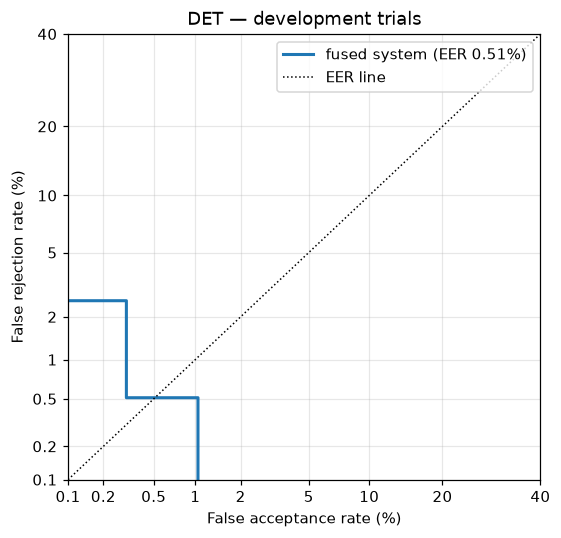

In [13]:
import matplotlib
import matplotlib.pyplot as plt

probit = lambda p: torch.special.ndtri(p.clamp(1e-4, 1 - 1e-4))
ticks = [0.001, 0.002, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.4]
fig, ax = plt.subplots(figsize=(5.2, 5))
_, far, frr = roc_points(dev_s, dev_y)
ax.plot(probit(far).tolist(), probit(frr).tolist(), lw=2, label=f"fused system (EER {e*100:.2f}%)")
ax.plot(probit(torch.tensor(ticks, dtype=torch.float64)).tolist(),
        probit(torch.tensor(ticks, dtype=torch.float64)).tolist(), "k:", lw=1, label="EER line")
tp = probit(torch.tensor(ticks, dtype=torch.float64)).tolist()
ax.set_xticks(tp); ax.set_xticklabels([f"{t*100:g}" for t in ticks])
ax.set_yticks(tp); ax.set_yticklabels([f"{t*100:g}" for t in ticks])
ax.set_xlim(tp[0], tp[-1]); ax.set_ylim(tp[0], tp[-1])
ax.set_xlabel("False acceptance rate (%)"); ax.set_ylabel("False rejection rate (%)")
ax.set_title("DET — development trials"); ax.grid(alpha=0.3); ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

## 9. Submission

Continuous scores (higher = stronger support for the claim), one per `trial_id`, in the
order of `eval_trials.csv`.  These are ranking scores — normalised LLRs, not calibrated
probabilities; the leaderboard metric (EER) depends only on their order.

In [14]:
eval_s = trial_scores(final["eval"], *index["eval"], "eval")
assert torch.isfinite(eval_s).all() and len(eval_s) == len(TRIALS["eval"])
sub_path = SUB_PATH
with open(sub_path, "w", newline="") as fh:
    wr = csv.writer(fh)
    wr.writerow(["trial_id", "score"])
    for t, s in zip(TRIALS["eval"], eval_s.tolist()):
        wr.writerow([t["trial_id"], f"{s:.6f}"])
dev_path = DEV_PATH
with open(dev_path, "w", newline="") as fh:
    wr = csv.writer(fh)
    wr.writerow(["claimed_id", "test_file", "label", "score"])
    for t, s in zip(TRIALS["dev"], dev_s.tolist()):
        wr.writerow([t["claimed_id"], t["test_file"], t["label"], f"{s:.6f}"])
# validate the file against the trial list
with open(sub_path, newline="") as fh:
    rows = list(csv.DictReader(fh))
assert [*rows[0]] == ["trial_id", "score"]
assert [r["trial_id"] for r in rows] == [t["trial_id"] for t in TRIALS["eval"]]
assert all(math.isfinite(float(r["score"])) for r in rows)
print(f"wrote {sub_path}: {len(rows)} rows, ids match eval_trials.csv, all scores finite")
print(f"wrote {dev_path}")
print(f"eval scores: mean {eval_s.mean():+.3f}, sd {eval_s.std():.3f}")

wrote submissions/final_submission.csv: 3524 rows, ids match eval_trials.csv, all scores finite
wrote results/dev_results_final.csv
eval scores: mean -3.855, sd 8.344


## 10. How the configuration was selected

The official dev list has only 196 genuine trials (one trial ≈ 0.5 % EER), and earlier
versions tuned on it lost 1–3 points on the leaderboard.  All final choices were therefore
made on an **eval-mirroring bench** (`svcore/bench.py`): 10 enrolment rotations of the five
dev takes per target (1,960 genuine trials) plus 4-fold background cross-validation in
which UBM, cohort and normalisation are refitted without the fold's speakers (368 genuine
trials).  Trial lists follow the organisers' recipe (3 other-target impostor trials per
target test file, 4 random claims per impostor-speaker file).

| system | bench EER |
|---|---|
| single IFD system, raw LLR | 1.74 % |
| single IFD system, T-norm (v3-style) | 1.41 % |
| v3 submission recipe (4 members, background S-norm) | 1.05 % |
| single IFD + adaptive S-norm with enrolled cohort + penalty | 0.99 % |
| **final: 3 IFD + 3 FDPD members** | **0.69 %** |

Rejected on the bench (no gain or worse): 64/256 components, LDA, temporal smoothing,
other magnitude-weight exponents, mean+variance MAP, larger cohorts, relative-phase-shift
(RPS) features, reverse/symmetric LLR, sub-band GMMs; exact group-delay cepstra were
dropped because their `|X|²` denominator lets magnitude into low-energy bins.